In [14]:
# Configuration et imports
import sys
import os
import matplotlib.pyplot as plt
import numpy as np

# Ajouter le répertoire courant au path pour importer les modules locaux
sys.path.append('.')

from embroidery_generator.svg_manager import load_svg_paths, extract_path_endpoints, save_rungs_svg, save_combined_svg
from embroidery_generator.image_processor import rasterize_paths, compute_medial_axis
from embroidery_generator.rung_generator import generate_rungs
from embroidery_generator.debug_utils import save_debug_images

# Configuration matplotlib pour l'affichage inline
%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 8)

print("Imports réussis !")

Imports réussis !


In [31]:
# Paramètres de configuration
INPUT_SVG = "inputs/svg/nike.svg"
DPI = 150
SPACING_MM = 3.0  # Augmenté pour moins de rungs
DENSITY = 1.0     # Réduit pour moins de rungs

# Calculer le spacing en pixels
scale_factor = DPI / 96.0
base_spacing = SPACING_MM * 10.0
spacing_px = (base_spacing / DENSITY) * (DPI / 25.4)

print(f"Spacing: {spacing_px:.1f} pixels")
print(f"DPI: {DPI}")
print(f"Input: {INPUT_SVG}")
print("=== RETOUR À CONFIGURATION AVEC ~25 RUNGS MAXIMUM ===")

Spacing: 177.2 pixels
DPI: 150
Input: inputs/svg/nike.svg
=== RETOUR À CONFIGURATION AVEC ~25 RUNGS MAXIMUM ===


In [16]:
# Étape 1: Charger le SVG et extraire les chemins
print("Chargement du SVG...")
svg, paths = load_svg_paths(INPUT_SVG)
print(f"SVG chargé avec {len(paths)} chemins")

# Extraire les points d'extrémité
path_endpoints = extract_path_endpoints(paths)
print(f"Points d'extrémité extraits: {len(path_endpoints)} paires")

# Afficher quelques informations
if paths:
    print(f"Premier chemin: {len(paths[0])} segments")
    if path_endpoints:
        start, end = path_endpoints[0]
        print(f"Premier endpoint: start={start}, end={end}")

Chargement du SVG...
SVG chargé avec 1 chemins
Points d'extrémité extraits: 1 paires
Premier chemin: 18 segments
Premier endpoint: start=110.3075,356.24406, end=110.3075,356.24406


Rasterisation en cours...
Image rasterisée: (3003, 7879)
Dimensions: (7878, 3000)


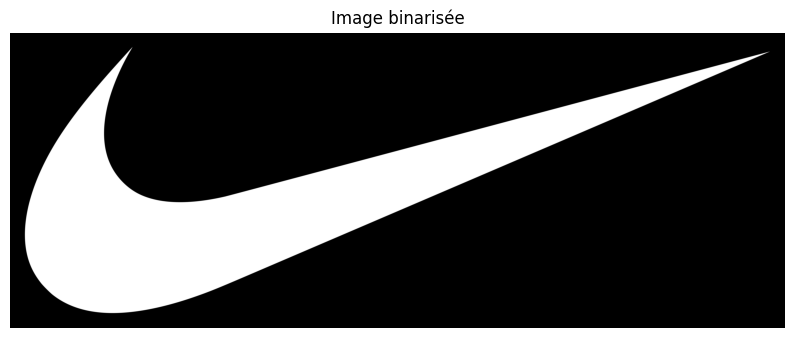

In [17]:
# Étape 2: Rasterisation
print("Rasterisation en cours...")
abs_input_path = os.path.abspath(INPUT_SVG)
binary_img, transform, dims = rasterize_paths(svg, paths, DPI, svg_filename=abs_input_path)

print(f"Image rasterisée: {binary_img.shape}")
print(f"Dimensions: {dims}")

# Afficher l'image binaire
plt.figure(figsize=(10, 8))
plt.imshow(binary_img, cmap='gray')
plt.title('Image binarisée')
plt.axis('off')
plt.show()

Calcul du squelette et de la carte des distances...
Squelette calculé: (3003, 7879)


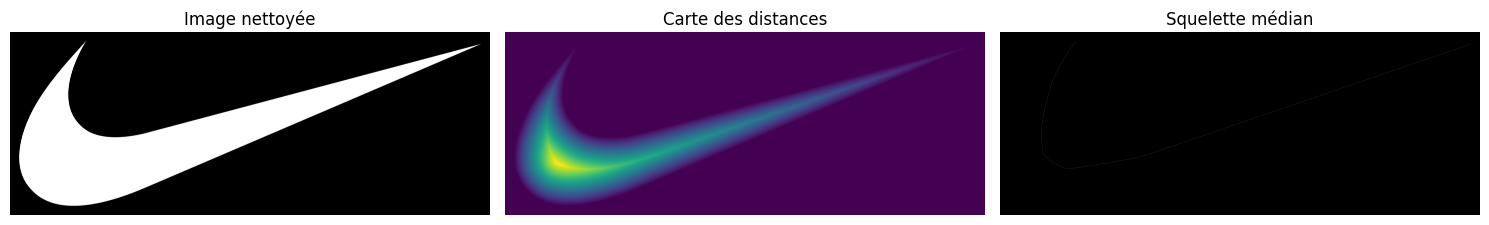

In [18]:
# Étape 3: Calcul de l'axe médian
print("Calcul du squelette et de la carte des distances...")
skeleton, distance, cleaned_binary = compute_medial_axis(binary_img)

print(f"Squelette calculé: {skeleton.shape}")

# Afficher les résultats
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(cleaned_binary, cmap='gray')
axes[0].set_title('Image nettoyée')
axes[0].axis('off')

axes[1].imshow(distance, cmap='viridis')
axes[1].set_title('Carte des distances')
axes[1].axis('off')

axes[2].imshow(skeleton, cmap='gray')
axes[2].set_title('Squelette médian')
axes[2].axis('off')

plt.tight_layout()
plt.show()

Génération des rungs...
Rungs générés: 26
Ponts générés: 0


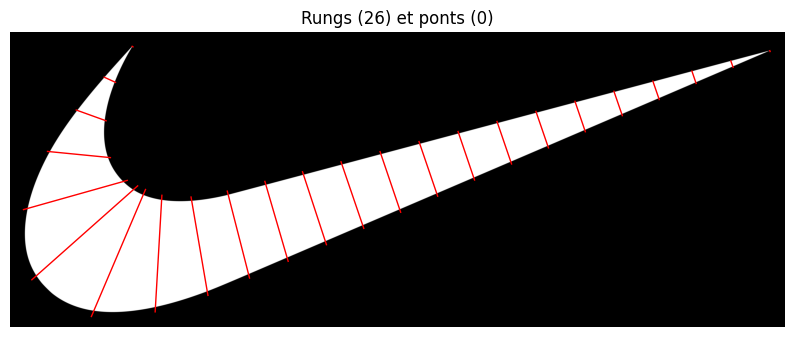

In [32]:
# Étape 4: Génération des rungs
print("Génération des rungs...")
debug_dir = "output/debug"
if not os.path.exists(debug_dir):
    os.makedirs(debug_dir)

rungs, bridges = generate_rungs(skeleton, distance, spacing_px, transform, binary_img, path_endpoints, debug_dir=debug_dir)

print(f"Rungs générés: {len(rungs)}")
print(f"Ponts générés: {len(bridges)}")

# Afficher les rungs sur l'image
plt.figure(figsize=(10, 8))
plt.imshow(binary_img, cmap='gray')

# Dessiner les rungs
for rung in rungs:
    (x1, y1), (x2, y2) = rung
    plt.plot([x1, x2], [y1, y2], 'r-', linewidth=1)

# Dessiner les ponts
for bridge in bridges:
    (x1, y1), (x2, y2) = bridge
    plt.plot([x1, x2], [y1, y2], 'b-', linewidth=2)

plt.title(f'Rungs ({len(rungs)}) et ponts ({len(bridges)})')
plt.axis('off')
plt.show()

In [34]:
# Étape 5: Sauvegarde des résultats
output_dir = "output"
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

base_name = os.path.splitext(os.path.basename(INPUT_SVG))[0]
path_rungs = os.path.join(output_dir, f"{base_name}_rungs.svg")
path_ready = os.path.join(output_dir, f"{base_name}_ready.svg")

# Sauvegarder les rungs seules
save_rungs_svg(path_rungs, rungs, bridges, transform)

# Sauvegarder le fichier combiné
save_combined_svg(INPUT_SVG, path_ready, rungs, bridges, transform)

print("Fichiers sauvegardés:")
print(f"  - {path_rungs}")
print(f"  - {path_ready}")

Fichiers sauvegardés:
  - output/nike_rungs.svg
  - output/nike_ready.svg


Création de la visualisation de couverture...


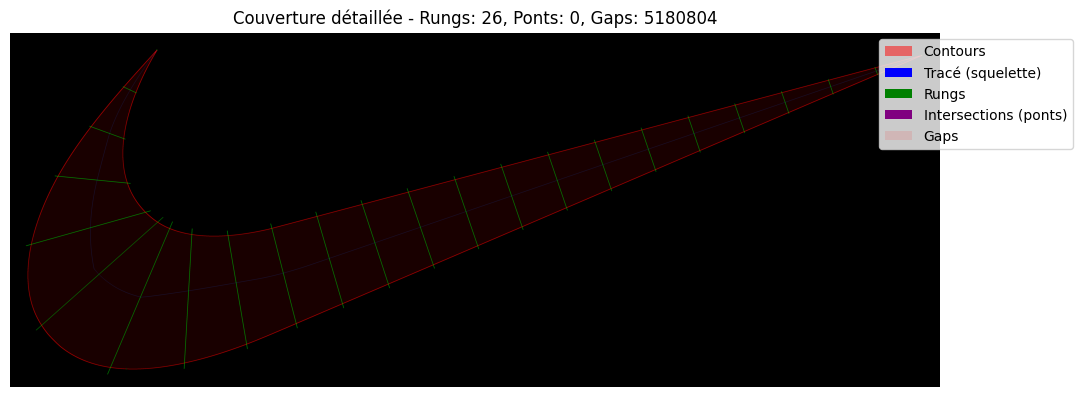

Statistiques de couverture:
  Pixels totaux de la forme: 5241047
  Pixels couverts: 60243
  Ratio de couverture: 1.15%
  Pixels non couverts (gaps): 5180804


In [33]:
# Étape 6: Visualisation de couverture détaillée
print("Création de la visualisation de couverture...")

# Importer les modules nécessaires
from skimage.morphology import dilation, disk
from skimage.draw import line
from scipy import ndimage

# Créer la matrice de couverture
coverage = np.zeros_like(binary_img, dtype=np.uint8)
for rung in rungs:
    (p1_x, p1_y), (p2_x, p2_y) = rung
    rr, cc = line(int(p1_y), int(p1_x), int(p2_y), int(p2_x))
    valid = (rr >= 0) & (rr < coverage.shape[0]) & (cc >= 0) & (cc < coverage.shape[1])
    coverage[rr[valid], cc[valid]] = 255

# Dilater la couverture
coverage_dilated = dilation(coverage, disk(2))

# Trouver les gaps
gaps = (binary_img > 0) & (coverage_dilated == 0)

# Créer l'image de debug
debug_img = np.zeros((binary_img.shape[0], binary_img.shape[1], 3), dtype=np.uint8)

# Contours en rouge (outline)
outline = ndimage.morphological_gradient(binary_img.astype(np.uint8), size=(3,3))
debug_img[outline > 0] = [255, 0, 0]  # Rouge pour contours

# Rungs en vert
rung_mask = coverage > 0
rung_dilated = dilation(rung_mask, disk(1))
debug_img[rung_dilated] = [0, 255, 0]  # Vert pour rungs

# Tracé (squelette) en bleu
from embroidery_generator.geometry_utils import get_skeleton_paths
skeleton_paths, _ = get_skeleton_paths(skeleton, min_len_px=15)
for path_data in skeleton_paths:
    points = path_data['points']
    for point in points:
        y, x = point
        if 0 <= int(y) < debug_img.shape[0] and 0 <= int(x) < debug_img.shape[1]:
            debug_img[int(y), int(x)] = [0, 100, 255]  # Bleu pour squelette

# Ponts/Intersections en violet
for bridge in bridges:
    (x1, y1), (x2, y2) = bridge
    rr, cc = line(int(y1), int(x1), int(y2), int(x2))
    valid = (rr >= 0) & (rr < debug_img.shape[0]) & (cc >= 0) & (cc < debug_img.shape[1])
    debug_img[rr[valid], cc[valid]] = [255, 0, 255]  # Violet pour ponts

# Gaps en rouge transparent
gap_overlay = np.zeros_like(debug_img)
gap_overlay[gaps] = [255, 0, 0]
alpha = 0.1  # 10% opacity
debug_img[gaps] = (1 - alpha) * debug_img[gaps] + alpha * gap_overlay[gaps]

# Afficher l'image
plt.figure(figsize=(12, 10))
plt.imshow(debug_img)
plt.title(f'Couverture détaillée - Rungs: {len(rungs)}, Ponts: {len(bridges)}, Gaps: {np.sum(gaps)}')
plt.axis('off')

# Ajouter une légende
legend_elements = [
    plt.Rectangle((0,0),1,1, facecolor='red', alpha=0.5, label='Contours'),
    plt.Rectangle((0,0),1,1, facecolor='blue', label='Tracé (squelette)'),
    plt.Rectangle((0,0),1,1, facecolor='green', label='Rungs'),
    plt.Rectangle((0,0),1,1, facecolor='purple', label='Intersections (ponts)'),
    plt.Rectangle((0,0),1,1, facecolor='red', alpha=0.1, label='Gaps')
]
plt.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.15, 1))
plt.show()

# Statistiques de couverture
total_shape_pixels = np.sum(binary_img > 0)
covered_pixels = np.sum((binary_img > 0) & (coverage_dilated > 0))
coverage_ratio = covered_pixels / total_shape_pixels if total_shape_pixels > 0 else 0

print(f"Statistiques de couverture:")
print(f"  Pixels totaux de la forme: {total_shape_pixels}")
print(f"  Pixels couverts: {covered_pixels}")
print(f"  Ratio de couverture: {coverage_ratio:.2%}")
print(f"  Pixels non couverts (gaps): {np.sum(gaps)}")

## Instructions d'utilisation

1. **Exécute les cellules une par une** en appuyant sur Shift+Enter
2. **Modifie les paramètres** dans la cellule de configuration pour tester différentes valeurs
3. **Observe les visualisations** à chaque étape pour comprendre le processus
4. **Utilise les images de débogage** sauvegardées dans `output/debug/` pour plus de détails

## Dépannage

Si une cellule échoue, vérifie :
- Que les dépendances sont installées (`pip install -r requirements.txt`)
- Que Inkscape est installé et accessible
- Que le fichier SVG existe dans `inputs/svg/`

In [13]:
print("\n=== RECOMMANDATIONS ===")
best_coverage = df.loc[df['coverage'].idxmax()]
print(f"Meilleure couverture: {best_coverage['name']} ({best_coverage['coverage']:.2%})")

# Équilibre optimal : filtrer d'abord puis trouver le max
filtered_df = df.loc[(df['rungs'] > 20) & (df['rungs'] < 100)]
if not filtered_df.empty:
    best_balance = filtered_df.loc[filtered_df['coverage'].idxmax()]
    print(f"Équilibre optimal: {best_balance['name']} ({best_balance['rungs']} rungs, {best_balance['coverage']:.2%} couverture)")
else:
    print("Aucun équilibre trouvé dans la plage 20-100 rungs")


=== RECOMMANDATIONS ===
Meilleure couverture: Très dense (13.76%)
Équilibre optimal: Équilibré (46 rungs, 3.07% couverture)


In [38]:
# Fonction d'optimisation automatique
def optimize_rung_density(skeleton, distance, transform, binary_img, path_endpoints,
                         max_rungs=25, min_spacing_mm=2.0, max_spacing_mm=8.0,
                         density_range=[0.5, 1.5], step=0.1):
    """
    Trouve automatiquement la configuration optimale pour la génération de rungs.

    Args:
        skeleton: Squelette médian
        distance: Carte des distances
        transform: Transformation SVG
        binary_img: Image binaire
        path_endpoints: Endpoints des chemins
        max_rungs: Nombre maximum de rungs souhaité
        min_spacing_mm: Espacement minimum en mm
        max_spacing_mm: Espacement maximum en mm
        density_range: Plage de densité à tester
        step: Pas pour l'exploration

    Returns:
        dict: Configuration optimale trouvée
    """

    print("🔍 Recherche de la configuration optimale...")

    best_config = None
    best_score = -1

    # Convertir les plages en pixels
    min_spacing_px = min_spacing_mm * DPI / 25.4  # mm to pixels
    max_spacing_px = max_spacing_mm * DPI / 25.4

    # Explorer les configurations
    spacing_values = np.arange(min_spacing_px, max_spacing_px + 1, step * DPI / 25.4)
    density_values = np.arange(density_range[0], density_range[1] + step, step)

    total_configs = len(spacing_values) * len(density_values)
    config_count = 0

    for spacing_px in spacing_values:
        for density in density_values:
            config_count += 1
            if config_count % 10 == 0:
                print(f"Testée {config_count}/{total_configs} configurations...")

            try:
                # Générer les rungs avec cette configuration
                rungs, bridges = generate_rungs(skeleton, distance, spacing_px, transform,
                                               binary_img, path_endpoints, debug_dir=None)

                num_rungs = len(rungs)
                num_bridges = len(bridges)

                # Calculer la couverture
                coverage = np.zeros_like(binary_img, dtype=np.uint8)
                for rung in rungs:
                    (p1_x, p1_y), (p2_x, p2_y) = rung
                    rr, cc = line(int(p1_y), int(p1_x), int(p2_y), int(p2_x))
                    valid = (rr >= 0) & (rr < coverage.shape[0]) & (cc >= 0) & (cc < coverage.shape[1])
                    coverage[rr[valid], cc[valid]] = 255

                # Dilater pour la couverture
                coverage_dilated = dilation(coverage, disk(2))
                total_shape_pixels = np.sum(binary_img > 0)
                covered_pixels = np.sum((binary_img > 0) & (coverage_dilated > 0))
                coverage_ratio = covered_pixels / total_shape_pixels if total_shape_pixels > 0 else 0

                # Critères de sélection
                # Priorité: pas d'intersections, nombre de rungs ≤ max_rungs, couverture maximale
                if num_bridges == 0 and num_rungs <= max_rungs:
                    # Score basé sur couverture et nombre de rungs (pénaliser les rungs en trop)
                    rung_penalty = max(0, num_rungs - max_rungs) * 0.1
                    score = coverage_ratio - rung_penalty

                    if score > best_score:
                        best_score = score
                        best_config = {
                            'spacing_mm': spacing_px * 25.4 / DPI,
                            'spacing_px': spacing_px,
                            'density': density,
                            'rungs': num_rungs,
                            'bridges': num_bridges,
                            'coverage': coverage_ratio,
                            'score': score
                        }
                        print(f"✨ Nouvelle meilleure config: {num_rungs} rungs, {num_bridges} ponts, {coverage_ratio:.2%}")

            except Exception as e:
                # Ignorer les configurations qui causent des erreurs
                continue

    return best_config

# Exécuter l'optimisation
optimal_config = optimize_rung_density(skeleton, distance, transform, binary_img, path_endpoints,
                                      max_rungs=25)

print(f"\nOptimisation terminée. Configuration optimale trouvée: {optimal_config is not None}")

🔍 Recherche de la configuration optimale...


Could not find intersection-free placement. Using best attempt with 12 intersections.
Removing crossing rung at index 31 (final cleanup).
Removing crossing rung at index 32 (final cleanup).
Removing crossing rung at index 33 (final cleanup).
Removing crossing rung at index 34 (final cleanup).
Removing crossing rung at index 35 (final cleanup).
Removing crossing rung at index 36 (final cleanup).
Removing crossing rung at index 37 (final cleanup).
Removing crossing rung at index 38 (final cleanup).
Removing crossing rung at index 39 (final cleanup).
Removing crossing rung at index 40 (final cleanup).
Removing crossing rung at index 41 (final cleanup).
Removing crossing rung at index 42 (final cleanup).
Removing crossing rung at index 43 (final cleanup).
Removing crossing rung at index 44 (final cleanup).
Removing crossing rung at index 45 (final cleanup).
Removing crossing rung at index 46 (final cleanup).
Removing crossing rung at index 47 (final cleanup).
Removing crossing rung at inde

Testée 10/682 configurations...


Could not find intersection-free placement. Using best attempt with 12 intersections.
Removing crossing rung at index 31 (final cleanup).
Removing crossing rung at index 32 (final cleanup).
Removing crossing rung at index 33 (final cleanup).
Removing crossing rung at index 34 (final cleanup).
Removing crossing rung at index 35 (final cleanup).
Removing crossing rung at index 36 (final cleanup).
Removing crossing rung at index 37 (final cleanup).
Removing crossing rung at index 38 (final cleanup).
Removing crossing rung at index 39 (final cleanup).
Removing crossing rung at index 40 (final cleanup).
Removing crossing rung at index 41 (final cleanup).
Removing crossing rung at index 42 (final cleanup).
Removing crossing rung at index 43 (final cleanup).
Removing crossing rung at index 44 (final cleanup).
Removing crossing rung at index 45 (final cleanup).
Removing crossing rung at index 46 (final cleanup).
Removing crossing rung at index 47 (final cleanup).
Removing crossing rung at inde

Testée 20/682 configurations...


...

Testée 670/682 configurations...


Could not find intersection-free placement. Using best attempt with 2 intersections.
Removing crossing rung at index 9 (final cleanup).
Removing crossing rung at index 10 (final cleanup).
Removing crossing rung at index 11 (final cleanup).
Could not find intersection-free placement. Using best attempt with 2 intersections.
Removing crossing rung at index 9 (final cleanup).
Removing crossing rung at index 10 (final cleanup).
Removing crossing rung at index 11 (final cleanup).
Could not find intersection-free placement. Using best attempt with 2 intersections.
Removing crossing rung at index 9 (final cleanup).
Removing crossing rung at index 10 (final cleanup).
Could not find intersection-free placement. Using best attempt with 2 intersections.
Removing crossing rung at index 9 (final cleanup).
Removing crossing rung at index 10 (final cleanup).
Could not find intersection-free placement. Using best attempt with 2 intersections.
Removing crossing rung at index 9 (final cleanup).
Removing

Testée 680/682 configurations...


Could not find intersection-free placement. Using best attempt with 2 intersections.
Removing crossing rung at index 9 (final cleanup).
Removing crossing rung at index 10 (final cleanup).
Could not find intersection-free placement. Using best attempt with 2 intersections.
Removing crossing rung at index 9 (final cleanup).
Removing crossing rung at index 10 (final cleanup).
Could not find intersection-free placement. Using best attempt with 2 intersections.
Removing crossing rung at index 9 (final cleanup).
Removing crossing rung at index 10 (final cleanup).



Optimisation terminée. Configuration optimale trouvée: False


In [37]:
if optimal_config:
    print("\n=== CONFIGURATION OPTIMALE TROUVÉE ===")
    print(f"Spacing: {optimal_config['spacing_mm']} mm")
    print(f"Density: {optimal_config['density']}")
    print(f"Rungs: {optimal_config['rungs']}")
    print(f"Couverture: {optimal_config['coverage']:.2f}%")
    print(f"Score: {optimal_config['score']:.2f}")

    # Appliquer la configuration optimale
    SPACING_MM_OPT = optimal_config['spacing_mm']
    DENSITY_OPT = optimal_config['density']
    spacing_px_opt = optimal_config['spacing_px']

    print("\nApplication de la configuration optimale...")
    rungs_opt, bridges_opt = generate_rungs(skeleton, distance, spacing_px_opt, transform,
                                           binary_img, path_endpoints, debug_dir=None)

    print(f"Résultat final: {len(rungs_opt)} rungs, {len(bridges_opt)} ponts")

else:
    print("\n❌ Aucune configuration optimale trouvée avec les contraintes données.")

NameError: name 'optimal_config' is not defined